# 04. Ajuste de hiperparámetros — OralSolutions

**Objetivo:** ajustar los **tres mejores candidatos del notebook 03**, identificados por PR-AUC media en validación cruzada temporal, con **30 configuraciones por modelo**. Se utilizan exactamente los mismos pliegues temporales con **60 días de maduración**.

**Familias seleccionadas en 03:** MLPClassifier (red neuronal), HistGradientBoosting (boosting) y LogisticRegression (lineal regularizada). El criterio de selección es `pr_auc_cv_mean`; la diferencia frente a la variación de pliegues se analiza después del tuning.

In [ ]:
import sys
import subprocess
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from scipy.stats import loguniform
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import average_precision_score

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.pipeline import (
    cargar_datos, obtener_datos_divididos, construir_pipeline,
    obtener_hash_datos, FECHA_CORTE, FECHA_EVENTO, SEMILLA,
)

HORIZONTE_DIAS = 60
N_CONFIGS = 30
EXPERIMENTO = 'OralSolutions'
MLFLOW_URI = 'http://localhost:5000'

mlflow.set_tracking_uri(MLFLOW_URI)
experimento = mlflow.get_experiment_by_name(EXPERIMENTO)
if experimento is None:
    raise RuntimeError('No existe el experimento OralSolutions: ejecuta primero el notebook 03.')
mlflow.set_experiment(EXPERIMENTO)
client = MlflowClient(tracking_uri=MLFLOW_URI)

X_train, _, y_train, _ = obtener_datos_divididos()
HASH_DATOS = obtener_hash_datos()
base = cargar_datos()
limite_train = pd.Timestamp(FECHA_CORTE) - pd.Timedelta(days=HORIZONTE_DIAS)
fechas_train = base.loc[base[FECHA_EVENTO] <= limite_train, FECHA_EVENTO].reset_index(drop=True)

commit = subprocess.run(
    ['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True
).stdout.strip() or 'sin_commit'

# Recuperar el ranking real de los cinco candidatos del notebook 03.
corridas = mlflow.search_runs(experiment_ids=[experimento.experiment_id])
candidatos = corridas.loc[
    corridas['tags.fase'].eq('candidato')
    & corridas['metrics.pr_auc_cv_mean'].notna()
].copy()
candidatos = candidatos.loc[candidatos['tags.snapshot_sha256'].eq(HASH_DATOS)]
# Si una corrida histórica contiene la misma huella, conservar solo la más reciente por nombre.
candidatos = candidatos.sort_values('start_time', ascending=False).drop_duplicates('tags.mlflow.runName')
candidatos = candidatos.sort_values('metrics.pr_auc_cv_mean', ascending=False)
if len(candidatos) < 5:
    raise RuntimeError('No se encontraron los cinco candidatos del notebook 03 con el hash actual.')
mejores_nombres = candidatos.head(3)['tags.mlflow.runName'].tolist()
permitidos = {'MLPClassifier_default', 'HistGradientBoosting_default', 'LogisticRegression_default',
            'RandomForest_default', 'GaussianNB_default'}
assert set(mejores_nombres).issubset(permitidos), mejores_nombres
print('Tres mejores candidatos:', mejores_nombres)
display(candidatos[['tags.mlflow.runName','metrics.pr_auc_cv_mean','metrics.pr_auc_cv_std']].head(5))
print('Hash:', HASH_DATOS)


=== DIVISIÓN TEMPORAL ===
Fecha de corte       : 2025-08-01
Horizonte            : 60 días
Límite entrenamiento : 2025-06-02
Train                : 1,195
Hold-out             : 826
Gap excluido         : 356
Tres mejores candidatos: ['MLPClassifier_default', 'HistGradientBoosting_default', 'LogisticRegression_default']


,tags.mlflow.runName,metrics.pr_auc_cv_mean,metrics.pr_auc_cv_std
1,MLPClassifier_default,0.177512,0.050635
2,HistGradientBoosting_default,0.169755,0.050386
4,LogisticRegression_default,0.166828,0.036239
0,GaussianNB_default,0.166766,0.053701
3,RandomForest_default,0.148897,0.050942


Hash: 11ae3cc53264511ef486f12d7a3fc0ddf2c6311e3ae7a8076f3c0cf046396dc1


## 1. Misma validación temporal que el notebook 03

Construimos los pliegues por fechas únicas: cada ventana de entrenamiento termina **como mínimo 60 días antes** de la primera fecha de validación. El preprocesador permanece dentro del `Pipeline`, por lo que se ajusta solo con cada bloque de entrenamiento.

In [ ]:
fechas_unicas = pd.Index(fechas_train.drop_duplicates().sort_values())
cv_temporal = []
resumen_cv = []
for i, (it, iv) in enumerate(TimeSeriesSplit(n_splits=5).split(fechas_unicas), 1):
    inicio_val = fechas_unicas[iv[0]]
    fin_val = fechas_unicas[iv[-1]]
    fin_train = inicio_val - pd.Timedelta(days=HORIZONTE_DIAS)
    idx_train = np.flatnonzero((fechas_train <= fin_train).to_numpy())
    idx_val = np.flatnonzero(((fechas_train >= inicio_val) & (fechas_train <= fin_val)).to_numpy())
    if not len(idx_train) or not len(idx_val):
        raise ValueError(f'Pliegue {i} vacío.')
    if y_train.iloc[idx_train].nunique() < 2 or y_train.iloc[idx_val].nunique() < 2:
        raise ValueError(f'Pliegue {i} sin ambas clases.')
    cv_temporal.append((idx_train, idx_val))
    resumen_cv.append({'pliegue': i, 'train': len(idx_train), 'validación': len(idx_val),
                        'último_train': fechas_train.iloc[idx_train].max().date(),
                        'primer_val': inicio_val.date()})
display(pd.DataFrame(resumen_cv))


,pliegue,train,validación,último_train,primer_val
0,1,34,134,2024-03-22,2024-05-21
1,2,136,172,2024-06-17,2024-08-16
2,3,259,204,2024-08-30,2024-10-29
3,4,435,255,2024-11-12,2025-01-11
4,5,651,334,2025-01-23,2025-03-24


## 2. Espacios de búsqueda y presupuesto

Se emplea `RandomizedSearchCV` con semilla 42, cinco pliegues y **30 configuraciones distintas por familia**. Se exploran tasas de aprendizaje y regularizaciones con escala logarítmica (`loguniform`), junto con arquitecturas y complejidades discretas. Las configuraciones se registran como **90 corridas hijas**, agrupadas bajo tres corridas padre.

In [ ]:
configuraciones = {
    'MLPClassifier_default': (
        'Red_Neuronal',
        construir_pipeline(MLPClassifier(max_iter=200, random_state=SEMILLA)),
        {'modelo__alpha': loguniform(1e-4, 1e1),
            'modelo__learning_rate_init': loguniform(1e-4, 1e-2),
            'modelo__hidden_layer_sizes': [(32,), (64,), (100,), (64, 32), (128, 64)],
            'modelo__early_stopping': [False, True]},
    ),
    'HistGradientBoosting_default': (
        'Boosting',
        construir_pipeline(HistGradientBoostingClassifier(random_state=SEMILLA), escalar_numericas=False),
        {'modelo__learning_rate': loguniform(0.01, 0.3),
            'modelo__l2_regularization': loguniform(1e-3, 10),
            'modelo__max_depth': [3, 4, 5, 6, None],
            'modelo__max_leaf_nodes': [15, 31, 63],
            'modelo__min_samples_leaf': [10, 20, 30, 50]},
    ),
    'LogisticRegression_default': (
        'Lineal_Regularizado',
        construir_pipeline(LogisticRegression(max_iter=1000, random_state=SEMILLA)),
        {'modelo__C': loguniform(1e-3, 1e2),
            'modelo__class_weight': [None, 'balanced']},
    ),
}

# Sólo se ajustan los tres mejores registrados en MLflow.
if not set(mejores_nombres).issubset(configuraciones):
    raise RuntimeError('Los mejores modelos incluyen una familia sin espacio de búsqueda definido; revisemos el ranking.')

resultados_tuning = []
for nombre_default in mejores_nombres:
    familia, estimador, espacio = configuraciones[nombre_default]
    nombre_padre = 'Tuning_' + nombre_default.removesuffix('_default')
    print(f'\nAjustando {nombre_padre} ({N_CONFIGS} configuraciones)...', flush=True)
    with mlflow.start_run(run_name=nombre_padre) as padre:
        inicio = time.perf_counter()
        busqueda = RandomizedSearchCV(
            estimator=estimador,
            param_distributions=espacio,
            n_iter=N_CONFIGS,
            cv=cv_temporal,
            scoring='average_precision',
            random_state=SEMILLA,
            n_jobs=1,
            return_train_score=True,
            refit=True,
            error_score='raise',
        )
        busqueda.fit(X_train, y_train)
        duracion = time.perf_counter() - inicio
        tabla_cv = pd.DataFrame(busqueda.cv_results_)

        # Una corrida hija por configuración efectivamente evaluada.
        for k, fila in tabla_cv.iterrows():
            with mlflow.start_run(run_name=f'{nombre_padre}_cfg_{k+1:02d}', nested=True):
                mlflow.log_params({
                    'hash_dataset': HASH_DATOS,
                    'fecha_corte': FECHA_CORTE,
                    'horizonte_dias': HORIZONTE_DIAS,
                    'semilla': SEMILLA,
                    **{p.replace('modelo__',''): str(v) for p,v in fila['params'].items()},
                })
                mlflow.log_metrics({
                    'pr_auc_train': float(fila['mean_train_score']),
                    'pr_auc_cv_mean': float(fila['mean_test_score']),
                    'pr_auc_cv_std': float(fila['std_test_score']),
                    'segundos_entrenamiento': float(fila['mean_fit_time']),
                })
                mlflow.set_tags({'fase': 'tuning_child', 'familia': familia, 'git_commit': commit})

        mejor = busqueda.best_estimator_
        pred_train = mejor.predict_proba(X_train)[:, 1]
        ap_train = float(average_precision_score(y_train, pred_train))
        ap_cv = float(busqueda.best_score_)
        std_cv = float(tabla_cv.loc[busqueda.best_index_, 'std_test_score'])
        ap_default = float(candidatos.loc[
            candidatos['tags.mlflow.runName'].eq(nombre_default), 'metrics.pr_auc_cv_mean'
        ].iloc[0])
        mejora = ap_cv - ap_default

        mlflow.log_params({
            'hash_dataset': HASH_DATOS,
            'tabla_origen': 'ORALSOLUTIONS_DW.OBT.OBT_RIESGO_ABANDONO + GOLD',
            'fecha_corte': FECHA_CORTE,
            'horizonte_dias': HORIZONTE_DIAS,
            'semilla': SEMILLA,
            'n_configs': N_CONFIGS,
            'cv_pliegues': 5,
            **{p.replace('modelo__',''): str(v) for p,v in busqueda.best_params_.items()},
        })
        mlflow.log_metrics({
            'pr_auc_train': ap_train, 'pr_auc_cv_mean': ap_cv,
            'pr_auc_cv_std': std_cv, 'mejora_cv_vs_default': mejora,
            'brecha_train_cv': ap_train-ap_cv,
            'segundos_entrenamiento': duracion,
        })
        mlflow.set_tags({'fase': 'tuning', 'familia': familia, 'git_commit': commit})
        ejemplo = X_train.iloc[:5].copy()
        firma = infer_signature(ejemplo, mejor.predict_proba(ejemplo))
        mlflow.sklearn.log_model(
            sk_model=mejor, artifact_path='model', signature=firma,
            input_example=ejemplo,
        )
        resultados_tuning.append({
            'modelo': nombre_padre, 'modelo_default': nombre_default,
            'familia': familia, 'run_id': padre.info.run_id,
            'pr_auc_default': ap_default,
            'pr_auc_cv_mean': ap_cv, 'pr_auc_cv_std': std_cv,
            'mejora_cv': mejora, 'pr_auc_train': ap_train,
            'brecha_train_cv': ap_train-ap_cv,
            'segundos_entrenamiento': duracion,
            'mejores_parametros': str(busqueda.best_params_),
        })
    print(f'Finalizado: CV={ap_cv:.4f} ± {std_cv:.4f}; mejora={mejora:+.4f}', flush=True)

df_tuning = pd.DataFrame(resultados_tuning).sort_values('pr_auc_cv_mean', ascending=False)
display(df_tuning)



Ajustando Tuning_MLPClassifier (30 configuraciones)...


c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warning

🏃 View run Tuning_MLPClassifier_cfg_01 at: http://localhost:5000/#/experiments/1/runs/ab0f860fcc3843d9892965097810a24c
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_MLPClassifier_cfg_02 at: http://localhost:5000/#/experiments/1/runs/85cc5a26840b42049519d903ec220c7c
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_MLPClassifier_cfg_03 at: http://localhost:5000/#/experiments/1/runs/4ce33cee17a4435b967e09ec61e7f6c2
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_MLPClassifier_cfg_04 at: http://localhost:5000/#/experiments/1/runs/d6572241b4264ea8baf7d71752703ae2
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_MLPClassifier_cfg_05 at: http://localhost:5000/#/experiments/1/runs/8e11eb101e16434d9b3321cbc606c0bb
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_MLPClassifier_cfg_06 at: http://localhost:5000/#/experiments/1/runs/3eeb33c48da747c6aec

c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from 

🏃 View run Tuning_MLPClassifier at: http://localhost:5000/#/experiments/1/runs/303bbd6f5077416682f5c065d6a0df1d
🧪 View experiment at: http://localhost:5000/#/experiments/1
Finalizado: CV=0.1886 ± 0.0352; mejora=+0.0111

Ajustando Tuning_HistGradientBoosting (30 configuraciones)...
🏃 View run Tuning_HistGradientBoosting_cfg_01 at: http://localhost:5000/#/experiments/1/runs/b32df748cf904925bab6938c97af7428
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_HistGradientBoosting_cfg_02 at: http://localhost:5000/#/experiments/1/runs/9d700b06f4d542c59db06618b119223e
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_HistGradientBoosting_cfg_03 at: http://localhost:5000/#/experiments/1/runs/d2680fbf962344c2a49cbea13f4df094
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_HistGradientBoosting_cfg_04 at: http://localhost:5000/#/experiments/1/runs/e10333be720643b9a687a3b5c9131d89
🧪 View experiment at: http://local

c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Tuning_HistGradientBoosting at: http://localhost:5000/#/experiments/1/runs/486b59d719de482aac58607cbce9d2c9
🧪 View experiment at: http://localhost:5000/#/experiments/1
Finalizado: CV=0.1852 ± 0.0597; mejora=+0.0155

Ajustando Tuning_LogisticRegression (30 configuraciones)...
🏃 View run Tuning_LogisticRegression_cfg_01 at: http://localhost:5000/#/experiments/1/runs/c7d987c4f00e455494bb004a4b634f16
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_LogisticRegression_cfg_02 at: http://localhost:5000/#/experiments/1/runs/c96e9552f8034e83ad7015329c1af2c2
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_LogisticRegression_cfg_03 at: http://localhost:5000/#/experiments/1/runs/bc1167f4bebc47959aed612214fd0ec2
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run Tuning_LogisticRegression_cfg_04 at: http://localhost:5000/#/experiments/1/runs/4058dc846476464d85459e7fe927b795
🧪 View experiment at: http://localhos

c:\Users\ANDRES\Desktop\proyecto_final\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run Tuning_LogisticRegression at: http://localhost:5000/#/experiments/1/runs/3faa7b3bfa2644ec8e41294909a9ff49
🧪 View experiment at: http://localhost:5000/#/experiments/1
Finalizado: CV=0.1829 ± 0.0202; mejora=+0.0161


,modelo,modelo_default,familia,run_id,pr_auc_default,pr_auc_cv_mean,pr_auc_cv_std,mejora_cv,pr_auc_train,brecha_train_cv,segundos_entrenamiento,mejores_parametros
0,Tuning_MLPClassifier,MLPClassifier_default,Red_Neuronal,303bbd6f5077416682f5c065d6a0df1d,0.177512,0.188618,0.035175,0.011107,0.442008,0.253389,20.648898,{'modelo__alpha': np.float64(0.000235913730634...
1,Tuning_HistGradientBoosting,HistGradientBoosting_default,Boosting,486b59d719de482aac58607cbce9d2c9,0.169755,0.185223,0.059669,0.015468,0.480568,0.295345,15.313868,{'modelo__l2_regularization': np.float64(0.020...
2,Tuning_LogisticRegression,LogisticRegression_default,Lineal_Regularizado,3faa7b3bfa2644ec8e41294909a9ff49,0.166828,0.182929,0.020221,0.016102,0.203627,0.020698,4.946471,"{'modelo__C': np.float64(73.92266140516048), '..."


## 3. Evidencia y comparación con los modelos por defecto

**Criterio de mejora:** una mejora de PR-AUC inferior a la desviación estándar entre pliegues no se considera evidencia sólida de mejora. Los dos finalistas se analizarán en `05_seleccion.ipynb`; **el hold-out permanece sin evaluar en este notebook**.

Resultados exportados: C:\Users\ANDRES\Desktop\proyecto_final\docs\resultados_tuning.csv


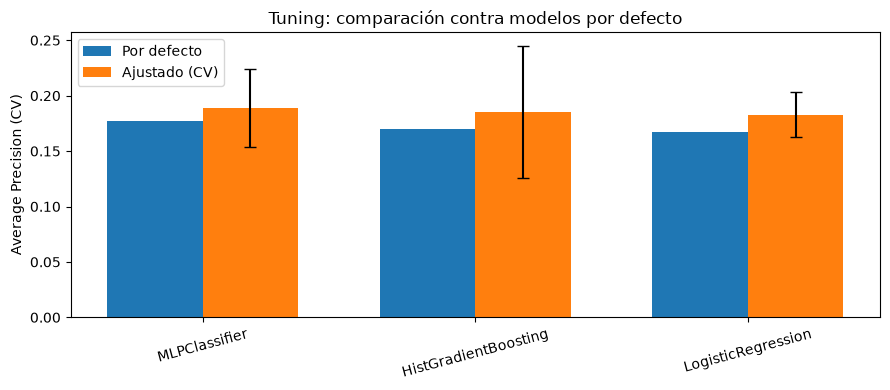

Tuning_MLPClassifier: mejora=+0.0111, std=0.0352, supera variación=no
Tuning_HistGradientBoosting: mejora=+0.0155, std=0.0597, supera variación=no
Tuning_LogisticRegression: mejora=+0.0161, std=0.0202, supera variación=no


In [ ]:
# Exportar únicamente CSV de resultados; los gráficos permanecen en el notebook.
ruta_csv = ROOT / 'docs' / 'resultados_tuning.csv'
ruta_csv.parent.mkdir(parents=True, exist_ok=True)
df_tuning.to_csv(ruta_csv, index=False, encoding='utf-8')
print(f'Resultados exportados: {ruta_csv}')

fig, ax = plt.subplots(figsize=(9,4))
x = np.arange(len(df_tuning))
w = 0.35
ax.bar(x-w/2, df_tuning['pr_auc_default'], width=w, label='Por defecto')
ax.bar(x+w/2, df_tuning['pr_auc_cv_mean'], width=w,
       yerr=df_tuning['pr_auc_cv_std'], capsize=4, label='Ajustado (CV)')
ax.set_xticks(x, df_tuning['modelo_default'].str.replace('_default','', regex=False), rotation=15)
ax.set_ylabel('Average Precision (CV)')
ax.set_title('Tuning: comparación contra modelos por defecto')
ax.legend()
plt.tight_layout()
plt.show()

for _, r in df_tuning.iterrows():
       robusta = 'sí' if r['mejora_cv'] > r['pr_auc_cv_std'] else 'no'
       print(f"{r['modelo']}: mejora={r['mejora_cv']:+.4f}, std={r['pr_auc_cv_std']:.4f}, supera variación={robusta}")


### 3.1. Interpretación del ajuste de hiperparámetros

La optimización produjo incrementos numéricos de PR-AUC respecto a las configuraciones por defecto: **+0,0111** para MLPClassifier, **+0,0155** para HistGradientBoosting y **+0,0161** para LogisticRegression.

Sin embargo, estas mejoras son menores que las desviaciones estándar observadas entre los cinco pliegues temporales de validación (**0,0352**, **0,0597** y **0,0202**, respectivamente). Por tanto, los resultados no proporcionan evidencia suficiente para afirmar que el ajuste de hiperparámetros haya producido una mejora robusta o estadísticamente significativa.

Las brechas entre entrenamiento y validación fueron especialmente pronunciadas en MLPClassifier (0,4420 frente a 0,1886) e HistGradientBoosting (0,4806 frente a 0,1852), lo que sugiere posibles dificultades de generalización.

**Conclusión:** el tuning permitió explorar sistemáticamente los espacios de hiperparámetros y registrar configuraciones reproducibles, pero sus beneficios predictivos no quedaron demostrados de manera robusta. Los modelos ajustados se mantienen como candidatos para el análisis posterior de costos operativos en `05_seleccion.ipynb`, sin utilizar el hold-out durante esta etapa.